# 02 - Quantization

In [4]:
import sys; sys.path.append("..")
%load_ext autoreload
%autoreload 2

import torch, torch.nn as nn
from src.data import get_dataloaders
from src.models import build_model
from src.metrics import count_parameters
from src.train import evaluate
from src.quant import *

device = torch.device("cpu")
_, val_loader, test_loader = get_dataloaders("../data", batch_size=128)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [ ]:
'''

# Check che il BN fuso dia lo stesso output del modello originale e che non ci siano più layer BN
for name in ["teacher", "student"]:
    model = build_model(name)
    model.load_state_dict(torch.load(f"../checkpoints/{name}_baseline.pt", map_location="cpu"))
    model.eval()
    folded = fold_bn(model)

    assert not any(isinstance(m, nn.BatchNorm2d) for m in folded.modules())

    x, _ = next(iter(val_loader))
    with torch.no_grad():
        diff = (model(x) - folded(x)).abs().max().item()
    _, acc_a = evaluate(model, val_loader, device)
    _, acc_b = evaluate(folded, val_loader, device)
    print(f"{name}: max |diff logits| = {diff:.2e} | val acc {acc_a * 100:.2f} -> {acc_b * 100:.2f}"
          f" | BN params {count_parameters(model)['bn']} -> {count_parameters(folded)['bn']}")

'''

teacher: max |diff logits| = 1.05e-05 | val acc 89.84 -> 89.84 | BN params 5504 -> 0
student: max |diff logits| = 9.54e-06 | val acc 74.92 -> 74.92 | BN params 460 -> 0


Quantizzazione e valutazione della quantizzazione

In [ ]:
# Quantization dei SOLI pesi

for name in ["teacher", "student"]:
    model = build_model(name)
    model.load_state_dict(torch.load(f"../checkpoints/{name}_baseline.pt", map_location="cpu"))
    folded = fold_bn(model)
    sim, qparams = quantize_model_weights(folded)

    # verifica: ogni peso ha errore al massimo scale/2 (limite teorico dell'arrotondamento)
    fm, sm = dict(folded.named_modules()), dict(sim.named_modules())
    for lname, (q, scale) in qparams.items():
        w, w_hat = fm[lname].weight.data, sm[lname].weight.data
        err = (w - w_hat).abs().reshape(w.shape[0], -1).amax(dim=1)
        assert torch.all(err <= scale / 2 + 1e-7), lname

    _, acc_fp = evaluate(folded, val_loader, device)
    _, acc_q = evaluate(sim, val_loader, device)
    print(f"{name}: val acc fp32 {acc_fp * 100:.2f} -> pesi int8 {acc_q * 100:.2f} "
          f"(Δ {(acc_q - acc_fp) * 100:+.2f})")

teacher: val acc fp32 89.84 -> pesi int8 89.84 (Δ +0.00)
student: val acc fp32 74.92 -> pesi int8 74.80 (Δ -0.12)


Mostro perchè serve una quantizzazione per-channel invece che per tensore

C:\Users\Pietr\AppData\Local\Temp\ipykernel_408\2148047312.py:15: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax[1].boxplot(ranges, labels=[n for n, _ in convs])


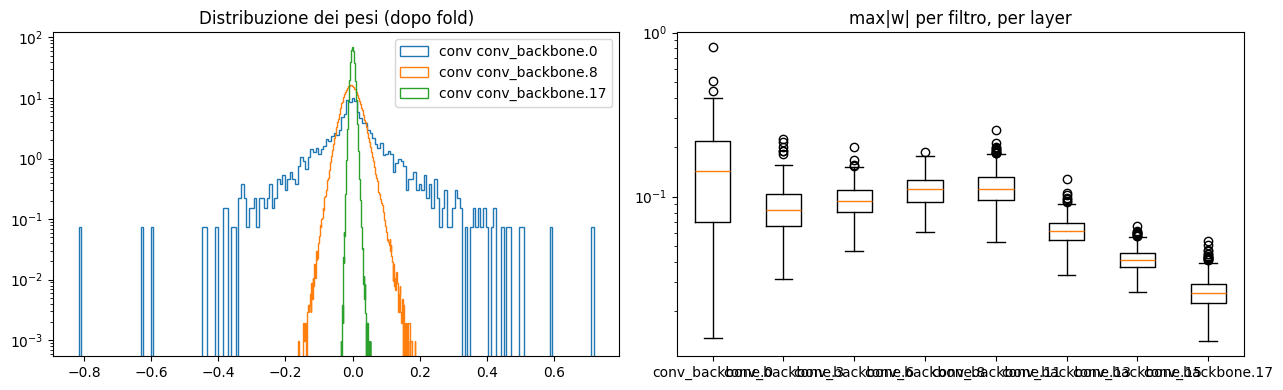

conv conv_backbone.0: con scala per-tensor il filtro più debole userebbe 2.1 livelli su 127
conv conv_backbone.3: con scala per-tensor il filtro più debole userebbe 17.8 livelli su 127
conv conv_backbone.6: con scala per-tensor il filtro più debole userebbe 29.4 livelli su 127
conv conv_backbone.8: con scala per-tensor il filtro più debole userebbe 41.0 livelli su 127
conv conv_backbone.11: con scala per-tensor il filtro più debole userebbe 26.4 livelli su 127
conv conv_backbone.13: con scala per-tensor il filtro più debole userebbe 32.9 livelli su 127
conv conv_backbone.15: con scala per-tensor il filtro più debole userebbe 49.9 livelli su 127
conv conv_backbone.17: con scala per-tensor il filtro più debole userebbe 31.1 livelli su 127


In [7]:
import matplotlib.pyplot as plt

model = build_model("teacher")
model.load_state_dict(torch.load("../checkpoints/teacher_baseline.pt", map_location="cpu"))
folded = fold_bn(model)
convs = [(n, m) for n, m in folded.named_modules() if isinstance(m, nn.Conv2d)]

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for n, m in [convs[0], convs[3], convs[-1]]:       # primo, quarto, ultimo conv
    ax[0].hist(m.weight.data.flatten().numpy(), bins=200, histtype="step",
               density=True, label=f"conv {n}")
ax[0].set_yscale("log"); ax[0].set_title("Distribuzione dei pesi (dopo fold)"); ax[0].legend()

ranges = [m.weight.data.reshape(m.weight.shape[0], -1).abs().amax(dim=1).numpy() for _, m in convs]
ax[1].boxplot(ranges, labels=[n for n, _ in convs])
ax[1].set_yscale("log"); ax[1].set_title("max|w| per filtro, per layer")
plt.tight_layout(); plt.show()

for n, m in convs:
    mx = m.weight.data.reshape(m.weight.shape[0], -1).abs().amax(dim=1)
    print(f"conv {n}: con scala per-tensor il filtro più debole userebbe "
          f"{127 * (mx.min() / mx.max()).item():.1f} livelli su 127")

Uso del modello quantizzato  (pesi e attivazioni) e analisi

In [ ]:
from src.quant import fold_bn, quantize_model_weights, build_w8a8_model, int8_model_size_mb
from src.metrics import profile_model, save_result

train_loader, val_loader, test_loader = get_dataloaders("../data", batch_size=128)

for name in ["teacher", "student"]:
    model = build_model(name)
    model.load_state_dict(torch.load(f"../checkpoints/{name}_baseline.pt", map_location="cpu"))
    folded = fold_bn(model)

    torch.manual_seed(0)  # il train_loader mescola: così la calibrazione è riproducibile
    qmodel, qparams, bias_q = build_w8a8_model(folded, train_loader, n_calib_batches=4)  # 4*128 = 512 immagini
    w8_only, _ = quantize_model_weights(folded)

    # ablation sulla val: quanto costano i pesi e quanto le attivazioni
    _, a_fp = evaluate(folded, val_loader, device)
    _, a_w8 = evaluate(w8_only, val_loader, device)
    _, a_w8a8 = evaluate(qmodel, val_loader, device)
    print(f"{name}: val fp32 {a_fp*100:.2f} | W8 {a_w8*100:.2f} | W8A8 {a_w8a8*100:.2f}")
    for i, fq in enumerate(qmodel.quantizers()):
        print(f"  act {i:2d}: [{fq.min_val.item():7.2f}, {fq.max_val.item():7.2f}] "
              f"scale {fq.scale.item():.4f} zp {int(fq.zero_point.item())}")

    # valutazione finale come gli altri modelli (la config è fissata: ora si usa il test)
    _, test_acc = evaluate(qmodel, test_loader, device)
    prof = profile_model(qmodel, dtype="int8", latency=False,
                         size_mb=int8_model_size_mb(qparams, bias_q, len(qmodel.quantizers())))
    save_result(f"{name}_int8", val_acc=a_w8a8, test_acc=test_acc, **prof)
    print(f"  test {test_acc*100:.2f} | {prof['size_mb']:.3f} MB | {prof['energy_uj']:.2f} µJ "
          f"| SRAM {prof['peak_act_kb']:.1f} KB\n")